In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from pathlib import Path

import seaborn as sns
sns.set_theme(style='whitegrid', font_scale=2, palette=sns.color_palette(),)
import matplotlib.pyplot as plt
import duckdb
import polars as pl

import userfm.plots

In [3]:
duckdb.sql("""
attach '../runs.sqlite';
use runs;
""")

# Dynamical system

### Lorenz '63

In [4]:
dataset_name = 'Lorenz63'
dataset_rows = duckdb.sql("""
select
    *
from Dataset
join DynamicalSystem on Dataset.id = DynamicalSystem.id
join Lorenz63 on DynamicalSystem.id = Lorenz63.id
where true
and batch_count_train = 0
and batch_count_val = 0
and batch_count_test = 0
and time_step_count = 90
""")
dataset_rows.show(max_width=120)
assert len(dataset_rows) == 1

┌────────────┬───────────────────┬─────────────────┬──────────────────┬───┬────────────────────┬───────────┬───────┐
│ batch_size │ batch_count_train │ batch_count_val │ batch_count_test │ … │        beta        │ rescaling │  id   │
│   int64    │       int64       │      int64      │      int64       │   │       double       │  double   │ int64 │
├────────────┼───────────────────┼─────────────────┼──────────────────┼───┼────────────────────┼───────────┼───────┤
│        500 │                 0 │               0 │                0 │ … │ 2.6666666666666665 │      20.0 │     4 │
├────────────┴───────────────────┴─────────────────┴──────────────────┴───┴────────────────────┴───────────┴───────┤
│ 1 rows                                                                                      16 columns (7 shown) │
└──────────────────────────────────────────────────────────────────────────────────────────────────────────────────┘



### FitzHugh-Nagumo

In [ ]:
dataset_name = 'FitzHughNagumo'
dataset_rows = duckdb.sql("""
select
    *
from Dataset
join DynamicalSystem on Dataset.id = DynamicalSystem.id
join FitzHughNagumo on DynamicalSystem.id = FitzHughNagumo.id
where true
and batch_count_train = 0
and batch_count_val = 0
and batch_count_test = 0
and time_step_count = 310
""")
dataset_rows.show(max_width=120)
assert len(dataset_rows) == 1

# Model

### Probability path

##### Conditional optimal transport

In [ ]:
probability_path_rows = duckdb.sql("""
select
    *
from ProbabilityPath
join ConditionalOT on ProbabilityPath.id = ConditionalOT.id
""")
probability_path_rows.show()
assert len(probability_path_rows) == 1

##### Variance exploding

In [5]:
probability_path_rows = duckdb.sql("""
select
    *
from ProbabilityPath
join VarianceExploding on ProbabilityPath.id = VarianceExploding.id
""")
probability_path_rows.show()
assert len(probability_path_rows) == 1

┌───────────────────┬───────┬──────────┬───────────┬───────────┬────────────────────────┬───────┐
│  sa_inheritance   │  id   │ time_min │ sigma_min │ sigma_max │ finzi_karras_weighting │  id   │
│      varchar      │ int64 │  double  │  double   │  double   │         int64          │ int64 │
├───────────────────┼───────┼──────────┼───────────┼───────────┼────────────────────────┼───────┤
│ VarianceExploding │     1 │    0.001 │     0.001 │     300.0 │                      1 │     1 │
└───────────────────┴───────┴──────────┴───────────┴───────────┴────────────────────────┴───────┘



### Steering

##### Source parallel tempering

In [6]:
spt_steering_rows = duckdb.sql(f"""
select
    *
from Steering
join SourceParallelTempering on Steering.id = SourceParallelTempering.id
where (tilt, update_count, chain_count) in (
    select
        SweepTilt.tilt, update_count, chain_count
    from SweepTrainedModel
    natural join BestSPTParameter
    cross join SweepTilt
    where penalization_power = 0
    and dynamical_system = {dataset_name!r}
    order by dynamical_system desc, SweepTilt.tilt
)
and symmetric_binary_reward;
""")
spt_steering_rows.show(max_width=120)

┌─────────────┬─────────────────────┬──────────────────────┬───────┬───┬─────────────┬──────────────┬────────┬───────┐
│ batch_count │ sampling_step_count │    sa_inheritance    │  id   │ … │ chain_count │ update_count │  tilt  │  id   │
│    int64    │        int64        │       varchar        │ int64 │   │    int64    │    int64     │ double │ int64 │
├─────────────┼─────────────────────┼──────────────────────┼───────┼───┼─────────────┼──────────────┼────────┼───────┤
│          64 │                 100 │ SourceParallelTemp…  │   299 │ … │           4 │            8 │    5.0 │   299 │
│          64 │                 100 │ SourceParallelTemp…  │   300 │ … │           4 │            8 │   10.0 │   300 │
│          64 │                 100 │ SourceParallelTemp…  │   301 │ … │           4 │            8 │   20.0 │   301 │
│          64 │                 100 │ SourceParallelTemp…  │   302 │ … │           4 │            8 │   40.0 │   302 │
├─────────────┴─────────────────────┴───────────

##### Feynman-Kac

In [7]:
fk_steering_rows = duckdb.sql(f"""
select
    *
from Steering
join FeynmanKac on Steering.id = FeynmanKac.id
join FeynmanKacIntermediateReward on FeynmanKac.FeynmanKacIntermediateReward = FeynmanKacIntermediateReward.id
join FeynmanKacIntermediateRewardExpectedSample on FeynmanKacIntermediateReward.id = FeynmanKacIntermediateRewardExpectedSample.id
where (tilt, potential, ensemble_size) in (
    select
        SweepTilt.tilt, potential, ensemble_size,
    from SweepTrainedModel
    natural join BestFKParameter
    cross join SweepTilt
    where penalization_power = 0
    and dynamical_system = {dataset_name!r}
    order by dynamical_system desc, SweepTilt.tilt
)
and symmetric_binary_reward;
""")
fk_steering_rows.show(max_width=120)

┌─────────────┬─────────────────────┬────────────────┬───────┬───┬──────────────────────┬───────┬───────┐
│ batch_count │ sampling_step_count │ sa_inheritance │  id   │ … │    sa_inheritance    │  id   │  id   │
│    int64    │        int64        │    varchar     │ int64 │   │       varchar        │ int64 │ int64 │
├─────────────┼─────────────────────┼────────────────┼───────┼───┼──────────────────────┼───────┼───────┤
│          64 │                 100 │ FeynmanKac    │   310 │ … │ FeynmanKacInterme…  │     1 │     1 │
│          64 │                 100 │ FeynmanKac    │   311 │ … │ FeynmanKacInterme…  │     1 │     1 │
│          64 │                 100 │ FeynmanKac    │   312 │ … │ FeynmanKacInterme…  │     1 │     1 │
│          64 │                 100 │ FeynmanKac    │   313 │ … │ FeynmanKacInterme…  │     1 │     1 │
├─────────────┴─────────────────────┴────────────────┴───────┴───┴──────────────────────┴───────┴───────┤
│ 4 rows                                              

### Model

In [8]:
model_rows = duckdb.sql("""
select
    *
from Model
join FlowMatching on Model.id = FlowMatching.id
join probability_path_rows on FlowMatching.ProbabilityPath = probability_path_rows.id
""")
model_rows.show(max_width=120)

┌────────────────┬───────┬─────────────┬────────┬───┬──────────┬───────────┬───────────┬──────────────────────┬───────┐
│ sa_inheritance │  id   │ epoch_count │   lr   │ … │ time_min │ sigma_min │ sigma_max │ finzi_karras_weigh…  │ id_1  │
│    varchar     │ int64 │    int64    │ double │   │  double  │  double   │  double   │        int64         │ int64 │
├────────────────┼───────┼─────────────┼────────┼───┼──────────┼───────────┼───────────┼──────────────────────┼───────┤
│ FlowMatching   │     1 │        2000 │ 0.0001 │ … │    0.001 │     0.001 │     300.0 │                    1 │     1 │
├────────────────┴───────┴─────────────┴────────┴───┴──────────┴───────────┴───────────┴──────────────────────┴───────┤
│ 1 rows                                                                                         17 columns (9 shown) │
└─────────────────────────────────────────────────────────────────────────────────────────────────────────────────────┘



# Rows

In [9]:
rows = duckdb.sql("""
select
    Conf.alt_id,
    steering_rows.*,
    dataset_rows.batch_size,
from Conf
join TrainingAndEvaluation on Conf.id = TrainingAndEvaluation.id
join dataset_rows on TrainingAndEvaluation.Dataset = dataset_rows.id
join Trained on TrainingAndEvaluation.Model = Trained.id
join (
    select id, tilt, sa_inheritance as steering, batch_count from spt_steering_rows
    union
    select id, tilt, sa_inheritance as steering, batch_count from fk_steering_rows
) as steering_rows on TrainingAndEvaluation.Steering = steering_rows.id
join TrainingAndEvaluation as TrainingAndEvaluation_trained on Trained.Conf = TrainingAndEvaluation_trained.id
join model_rows on TrainingAndEvaluation_trained.Model = model_rows.id
where true
and not TrainingAndEvaluation.log_constraint_values
""")
rows.show(max_width=120)

┌──────────┬───────┬────────┬─────────────────────────┬─────────────┬────────────┐
│  alt_id  │  id   │  tilt  │        steering         │ batch_count │ batch_size │
│ varchar  │ int64 │ double │         varchar         │    int64    │   int64    │
├──────────┼───────┼────────┼─────────────────────────┼─────────────┼────────────┤
│ 95bkwfod │   313 │   40.0 │ FeynmanKac             │          64 │        500 │
│ 0y3y6670 │   312 │   20.0 │ FeynmanKac             │          64 │        500 │
│ nh82zcqn │   311 │   10.0 │ FeynmanKac             │          64 │        500 │
│ dyhcek5w │   310 │    5.0 │ FeynmanKac             │          64 │        500 │
│ 5no87fr1 │   302 │   40.0 │ SourceParallelTempering │          64 │        500 │
│ ufou3hgo │   301 │   20.0 │ SourceParallelTempering │          64 │        500 │
│ pq8dhnab │   300 │   10.0 │ SourceParallelTempering │          64 │        500 │
│ qpqsdxqq │   299 │    5.0 │ SourceParallelTempering │          64 │        500 │
└───────

In [10]:
metrics = (
    pl.scan_csv([
        f'~/out/user-defined-events/runs/{alt_id}/metrics.csv'
        for alt_id, in duckdb.sql("select alt_id from rows").fetchall()
    ], include_file_paths='file_path')
    .with_columns(alt_id=pl.col('file_path').str.split('/').list.get(-2))
    .collect()
)
metrics = duckdb.sql("""
select
    *
from rows
join metrics on rows.alt_id = metrics.alt_id
""")
metrics.show(max_width=120)

┌──────────┬───────┬────────┬──────────────────────┬───┬───────┬──────────────────────┬──────────┐
│  alt_id  │  id   │  tilt  │       steering       │ … │ step  │      file_path       │  alt_id  │
│ varchar  │ int64 │ double │       varchar        │   │ int64 │       varchar        │ varchar  │
├──────────┼───────┼────────┼──────────────────────┼───┼───────┼──────────────────────┼──────────┤
│ 95bkwfod │   313 │   40.0 │ FeynmanKac          │ … │    63 │ /home/ttransue/out…  │ 95bkwfod │
│ 0y3y6670 │   312 │   20.0 │ FeynmanKac          │ … │    63 │ /home/ttransue/out…  │ 0y3y6670 │
│ nh82zcqn │   311 │   10.0 │ FeynmanKac          │ … │    63 │ /home/ttransue/out…  │ nh82zcqn │
│ dyhcek5w │   310 │    5.0 │ FeynmanKac          │ … │    63 │ /home/ttransue/out…  │ dyhcek5w │
│ 5no87fr1 │   302 │   40.0 │ SourceParallelTemp…  │ … │    63 │ /home/ttransue/out…  │ 5no87fr1 │
│ ufou3hgo │   301 │   20.0 │ SourceParallelTemp…  │ … │    63 │ /home/ttransue/out…  │ ufou3hgo │
│ pq8dhnab │  

┌──────────┬────────┬─────────────────────────┬───────────────────────────┬──────────────┐
│  alt_id  │  tilt  │        steering         │ satisfactory_sample_total │ success_rate │
│ varchar  │ double │         varchar         │          double           │    double    │
├──────────┼────────┼─────────────────────────┼───────────────────────────┼──────────────┤
│ dyhcek5w │    5.0 │ FeynmanKac             │                   21665.0 │   0.67703125 │
│ qpqsdxqq │    5.0 │ SourceParallelTempering │                   30812.0 │     0.962875 │
│ nh82zcqn │   10.0 │ FeynmanKac             │                   21668.0 │     0.677125 │
│ pq8dhnab │   10.0 │ SourceParallelTempering │                   31705.0 │   0.99078125 │
│ ufou3hgo │   20.0 │ SourceParallelTempering │                   31746.0 │    0.9920625 │
│ 0y3y6670 │   20.0 │ FeynmanKac             │                   21668.0 │     0.677125 │
│ 95bkwfod │   40.0 │ FeynmanKac             │                   21668.0 │     0.677125 │
│ 5

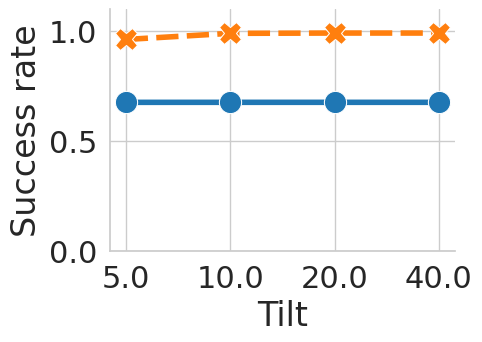

In [11]:
data = duckdb.sql("""
select
    alt_id,
    tilt,
    steering,
    sum(satisfactory_sample_count) as satisfactory_sample_total,
    satisfactory_sample_total / (batch_count * batch_size) as success_rate,
from metrics
group by alt_id, tilt, steering, batch_count, batch_size,
order by tilt
""")
data.show()
data = data.pl()
order = ['FeynmanKac', 'SourceParallelTempering']
include_legend = False
plot = (
    sns.relplot(
        kind='line',
        markers=True,
        markersize=16,
        linewidth=4,
        height=4,
        aspect=1.3,
        legend=include_legend,
        data=data,
        x='tilt',
        y='success_rate',
        hue='steering',
        hue_order=order,
        style='steering',
        style_order=order,
    )
    .set(
        xscale='log',
        xticks=data['tilt'].unique(),
        xticklabels=data['tilt'].unique(),
        xlabel='Tilt',
        ylabel='Success rate',
        ylim=(.0, 1.1),
        # yticks=[0, .5, 1],
    )
)
if include_legend:
    sns.move_legend(
        plot,
        loc='upper center',
        labels=['FK', 'SPT'],
        ncol=4,
        title='',
        bbox_to_anchor=(.400, 1.18),
        frameon=True,
        fancybox=True,
    )
ax = plot.axes[0, 0]
ax.minorticks_off()

In [12]:
if include_legend:
    userfm.plots.save_legend(plot, 'AblateTilt')
plot.savefig('AblateTilt.pdf', format='pdf', bbox_inches='tight', pad_inches=.06)